In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

path = Path("../data/environmental/resolve_2017")
shapefile = next(path.rglob("*.shp"))

resolve = gpd.read_file(shapefile)

print(resolve.columns)
print(resolve.crs)
print(resolve.shape)

resolve.head()

Index(['OBJECTID', 'ECO_NAME', 'BIOME_NUM', 'BIOME_NAME', 'REALM',
       'ECO_BIOME_', 'NNH', 'ECO_ID', 'SHAPE_LENG', 'SHAPE_AREA', 'NNH_NAME',
       'COLOR', 'COLOR_BIO', 'COLOR_NNH', 'LICENSE', 'geometry'],
      dtype='str')
EPSG:4326
(847, 16)


,OBJECTID,ECO_NAME,BIOME_NUM,BIOME_NAME,REALM,ECO_BIOME_,NNH,ECO_ID,SHAPE_LENG,SHAPE_AREA,NNH_NAME,COLOR,COLOR_BIO,COLOR_NNH,LICENSE,geometry
0,1.0,Adelie Land tundra,11.0,Tundra,Antarctica,AN11,1,117,9.749780,0.038948,Half Protected,#63CFAB,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((158.7141 -69.60657, 158.71264 ..."
1,2.0,Admiralty Islands lowland rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Australasia,AU01,2,135,4.800349,0.170599,Nature Could Reach Half Protected,#70A800,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((147.28819 -2.57589, 147.2715 -..."
2,3.0,Aegean and Western Turkey sclerophyllous and m...,12.0,"Mediterranean Forests, Woodlands & Scrub",Palearctic,PA12,4,785,162.523044,13.844952,Nature Imperiled,#FF7F7C,#FE0000,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((26.88659 35.32161, 26.88297 35..."
3,4.0,Afghan Mountains semi-desert,13.0,Deserts & Xeric Shrublands,Palearctic,PA13,4,807,15.084037,1.355536,Nature Imperiled,#FA774D,#CC6767,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((65.48655 34.71401, 65.52872 34..."
4,5.0,Ahklun and Kilbuck Upland Tundra,11.0,Tundra,Nearctic,NE11,1,404,22.590087,8.196573,Half Protected,#4C82B6,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((-160.26404 58.64097, -160.2673..."


In [ ]:
resolve_core = resolve[
    [
        "ECO_ID",
        "ECO_NAME",
        "BIOME_NUM",
        "BIOME_NAME",
        "REALM",
        "geometry"
    ]
].copy()

In [ ]:
print("Records:", len(resolve_core))
print("Unique ecoregion IDs:", resolve_core.ECO_ID.nunique())
print("Unique biome IDs:", resolve_core.BIOME_NUM.nunique())
print("Invalid geometries:", (~resolve_core.geometry.is_valid).sum())
print("Empty geometries:", resolve_core.geometry.is_empty.sum())

resolve_core.groupby(
    ["BIOME_NUM", "BIOME_NAME"],
    dropna=False
).size()

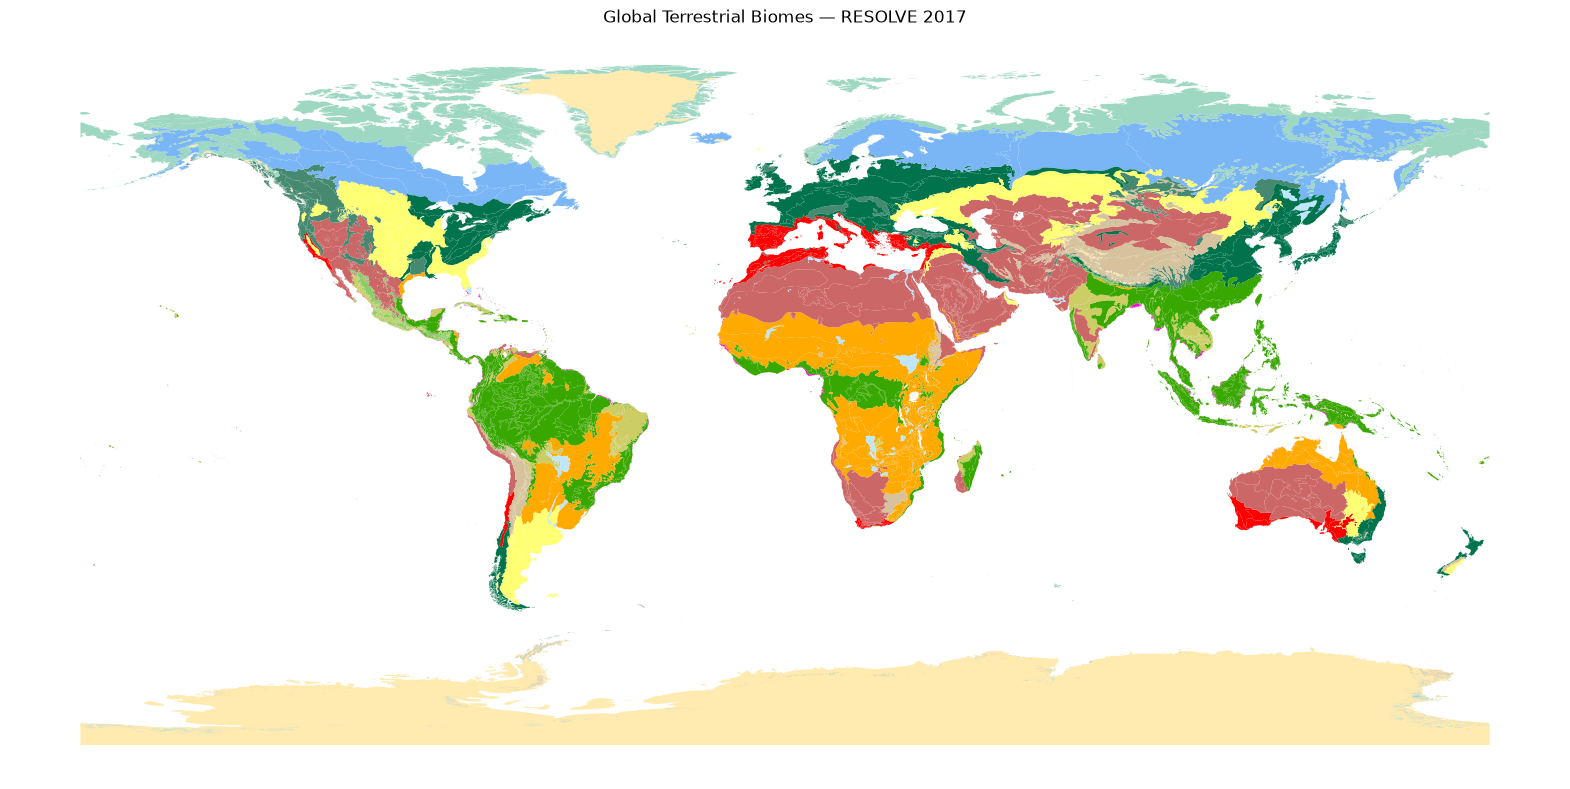

In [13]:
fig, ax = plt.subplots(figsize=(20, 12))

resolve.plot(
    ax=ax,
    color=resolve["COLOR_BIO"],
    linewidth=0
)

ax.set_title("Global Terrestrial Biomes — RESOLVE 2017")
ax.set_axis_off()

plt.show()

C:\Users\Stefano\AppData\Local\Temp\ipykernel_41624\1871771947.py:3: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  resolve.plot(


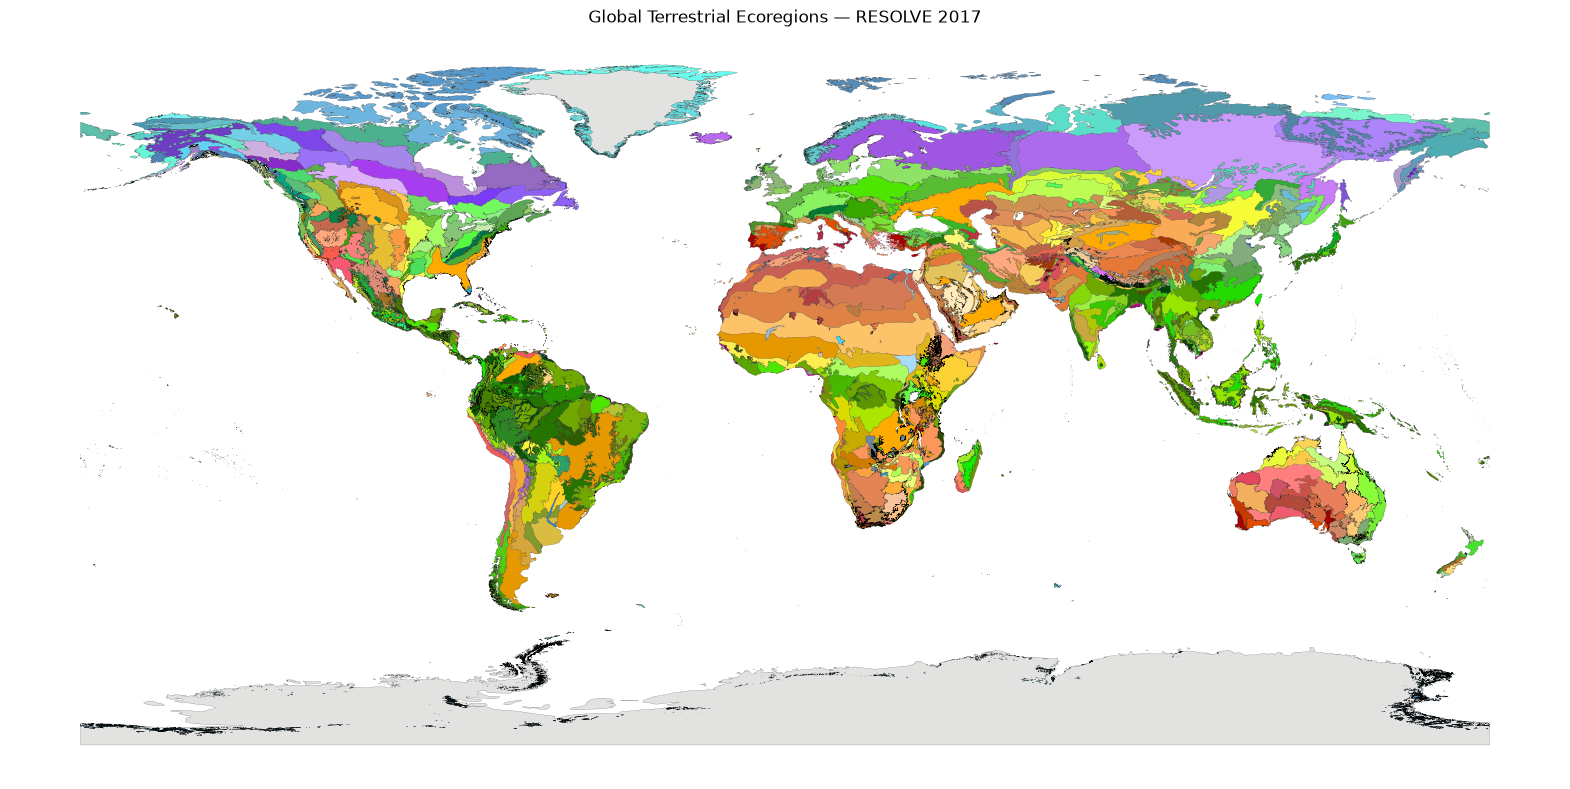

In [16]:
fig, ax = plt.subplots(figsize=(20, 12))

resolve.plot(
    ax=ax,
    column="ECO_ID",
    categorical=True,
    color=resolve["COLOR"],
    linewidth=0.1,
    edgecolor="black"
)

ax.set_title("Global Terrestrial Ecoregions — RESOLVE 2017")
ax.set_axis_off()

plt.show()